# TP3 — RAG Multimodal Agentique avec LangGraph

**Source documentaire :** *Attention Is All You Need* (Vaswani et al., 2017)

Pipeline (cf. schéma du cours) :

`PDF → PyMuPDF → textes + images → CLIP (espace latent commun) → ChromaDB → retriever_tool → Agent ReAct (MIND + BODY) avec LangGraph`

| Étape | Contenu |
|---|---|
| 1 | Extraction du contenu multimodal (textes & images) |
| 2 | Embeddings CLIP normalisés |
| 3 | Indexation dans ChromaDB (SHA-256, métadonnées) |
| 4 | Recherche multimodale par similarité cosinus |
| 5 | Le retriever devient un outil : `retriever_tool` |
| 6 | Agent ReAct MIND/BODY avec LangGraph |
| 7 | Tests et validation |

## Étape 1 — Extraction du contenu multimodal (textes & images)

On utilise **PyMuPDF** comme dans le cours :
- le texte de chaque page est enregistré dans `resultats_pdf/textes/page_XXX.txt`, et l'ensemble dans `resultats_pdf/texte_complet.txt` ;
- les images intégrées au PDF sont enregistrées dans `resultats_pdf/images/page_XXX_image_<xref>.<ext>`.

Le numéro de page est conservé dans le nom des fichiers : il sera relu à l'étape 3 pour les métadonnées.
Le découpage en fragments (chunks) adaptés à CLIP est fait à l'étape 2, une fois le tokenizer chargé.

In [1]:
from pathlib import Path
import pymupdf

PDF_PATH = Path("attention is all you need.pdf")

OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"

if not PDF_PATH.is_file():
    raise FileNotFoundError(f"Fichier introuvable : {PDF_PATH.resolve()}")

TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDF : {PDF_PATH.name}")
print(f"Résultats : {OUTPUT_DIR}/")

PDF : attention is all you need.pdf
Résultats : resultats_pdf/


In [2]:
textes = []
nombre_images = 0
pages_sans_texte = []

with pymupdf.open(PDF_PATH) as document:
    nombre_pages = len(document)

    for numero_page, page in enumerate(document, start=1):
        # ---- Extraction du texte (ordre de lecture approximatif) ----
        texte = page.get_text("text", sort=True)

        fichier_texte = TEXT_DIR / f"page_{numero_page:03d}.txt"
        fichier_texte.write_text(texte, encoding="utf-8")

        textes.append(f"===== PAGE {numero_page} =====\n\n{texte}")

        if not texte.strip():
            pages_sans_texte.append(numero_page)

        # ---- Extraction des images intégrées ----
        images_vues = set()  # éviter les doublons sur une même page

        for image_info in page.get_images(full=True):
            xref = image_info[0]
            if xref in images_vues:
                continue
            images_vues.add(xref)

            try:
                image = document.extract_image(xref)
                if not image:
                    print(f"Image non extractible : page {numero_page}, xref {xref}")
                    continue

                fichier_image = IMAGE_DIR / f"page_{numero_page:03d}_image_{xref}.{image['ext']}"
                fichier_image.write_bytes(image["image"])
                nombre_images += 1

            except Exception as erreur:
                print(f"Erreur d'extraction : page {numero_page}, image {xref} : {erreur}")

# Texte complet du document
(OUTPUT_DIR / "texte_complet.txt").write_text("\n\n".join(textes), encoding="utf-8")

print(f"Pages traitées : {nombre_pages}")
print(f"Images enregistrées : {nombre_images}")
if pages_sans_texte:
    print("Pages sans texte détectable :", pages_sans_texte)

Pages traitées : 11
Images enregistrées : 3


### Vérification de l'extraction

On contrôle : le nombre de caractères par page, le début du texte complet et l'aperçu des images extraites (avec leur page).

page_001.txt :   3275 caractères
page_002.txt :   4310 caractères
page_003.txt :   1832 caractères
page_004.txt :   2629 caractères
page_005.txt :   3460 caractères
page_006.txt :   3865 caractères
page_007.txt :   3315 caractères
page_008.txt :   3820 caractères
page_009.txt :   4058 caractères
page_010.txt :   3274 caractères
page_011.txt :   2471 caractères

APERÇU DU TEXTE

===== PAGE 1 =====

             Attention Is All You Need





     Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗
      Google Brain          Google Brain       Google Research     Google Research
  avaswani@google.com   noam@google.com   nikip@google.com   usz@google.com

        Llion Jones∗          Aidan N. Gomez∗†            Łukasz Kaiser∗
     Google Research          University of Toronto              Google Brain
    llion@google.com     aidan@cs.toronto.edu     lukaszkaiser@google.com

                                               Illia Polosukhin∗‡
                       

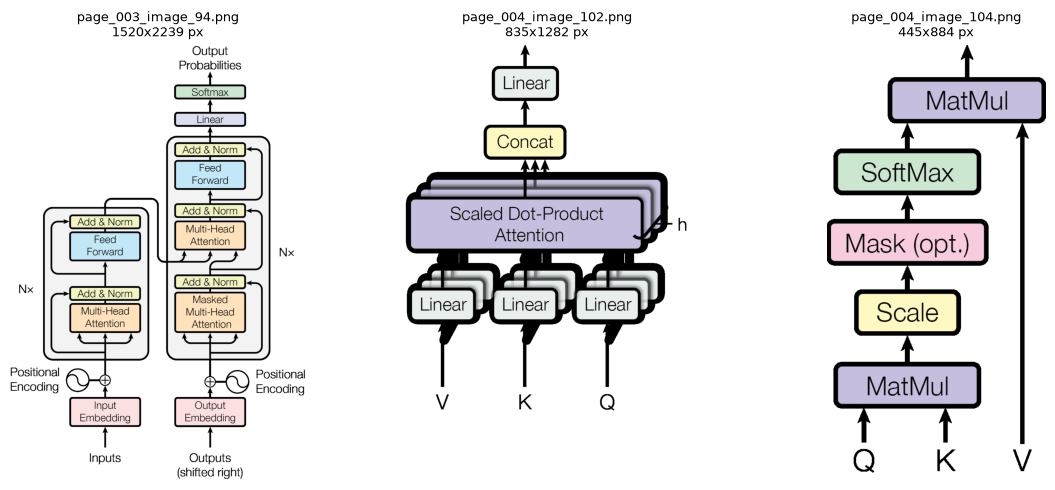

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

# 1. Volume de texte par page
for fichier in sorted(TEXT_DIR.glob("page_*.txt")):
    print(f"{fichier.name} : {len(fichier.read_text(encoding='utf-8')):>6} caractères")

# 2. Aperçu du texte complet
texte_complet = (OUTPUT_DIR / "texte_complet.txt").read_text(encoding="utf-8")
print("\nAPERÇU DU TEXTE\n")
print(texte_complet[:800])

# 3. Aperçu des images extraites
fichiers_images = sorted(IMAGE_DIR.iterdir())
fig, axes = plt.subplots(1, len(fichiers_images), figsize=(4 * len(fichiers_images), 5))
for ax, fichier in zip(list(axes) if len(fichiers_images) > 1 else [axes], fichiers_images):
    with Image.open(fichier) as image:
        ax.imshow(image.convert("RGB"))
        ax.set_title(f"{fichier.name}\n{image.size[0]}x{image.size[1]} px", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Étape 2 — Vectorisation dans un espace latent commun (CLIP)

**CLIP** possède deux encodeurs (texte et image) entraînés ensemble pour projeter textes et images
dans **le même espace vectoriel** : le vecteur d'une image est proche de celui de sa description.

- Modèle : `ViT-B-32` (Vision Transformer, patchs de 32×32 px), poids `laion2b_s34b_b79k` (open_clip).
- Chaque embedding a **512 dimensions**.
- Les vecteurs sont **normalisés (norme L2 = 1)** : le produit scalaire de deux vecteurs est alors leur **similarité cosinus**.

> Si l'on change de modèle ou de poids, il faut une nouvelle collection : les embeddings de modèles différents ne sont pas comparables.

In [4]:
import torch
import open_clip
from open_clip.tokenizer import SimpleTokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

model, _, preprocess = open_clip.create_model_and_transforms(MODEL_NAME, pretrained=PRETRAINED)
model = model.to(DEVICE).eval()

tokenizer = open_clip.get_tokenizer(MODEL_NAME)  # texte -> tokens au format CLIP (77 positions)
bpe = SimpleTokenizer()                           # tokenizer BPE brut, pour compter/découper

print("Appareil :", DEVICE)
print("Modèle :", MODEL_NAME, "|", PRETRAINED)

/Users/hajdaoui/IA GENERATIVE MULTI-MODALE/TP3/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Appareil : cpu
Modèle : ViT-B-32 | laion2b_s34b_b79k


### Découpage du texte en fragments (chunks)

L'encodeur de texte de CLIP accepte au maximum **77 tokens**. Le texte de chaque page est donc découpé
en fragments de **60 tokens BPE** avec un **chevauchement de 10 tokens** (méthode du cours),
pour garder du contexte aux frontières entre deux fragments.

In [5]:
def decouper_texte(texte, taille=60, chevauchement=10):
    """Découper le texte en fragments courts adaptés à CLIP."""
    if not 0 <= chevauchement < taille:
        raise ValueError("Le chevauchement doit être inférieur à la taille.")

    tokens = bpe.encode(texte)

    for debut in range(0, len(tokens), taille - chevauchement):
        fragment = bpe.decode(tokens[debut:debut + taille]).strip()
        if fragment:
            yield fragment
        if debut + taille >= len(tokens):
            break


# Découpage de toutes les pages en conservant le numéro de page
fragments_par_page = {
    int(fichier.stem.split("_")[1]): list(decouper_texte(fichier.read_text(encoding="utf-8")))
    for fichier in sorted(TEXT_DIR.glob("page_*.txt"))
}

for page, fragments in fragments_par_page.items():
    print(f"Page {page:>2} : {len(fragments):>3} fragments")
print("Total :", sum(len(f) for f in fragments_par_page.values()), "fragments")

print("\nExemple (page 3, fragment 0) :\n", fragments_par_page[3][0])
print("\nLongueur max d'un fragment après tokenisation CLIP :",
      max(len(bpe.encode(f)) for fs in fragments_par_page.values() for f in fs), "tokens BPE (< 77)")

Page  1 :  13 fragments
Page  2 :  18 fragments
Page  3 :   8 fragments
Page  4 :  11 fragments
Page  5 :  16 fragments
Page  6 :  17 fragments
Page  7 :  16 fragments
Page  8 :  19 fragments
Page  9 :  16 fragments
Page 10 :  21 fragments
Page 11 :  16 fragments
Total : 171 fragments

Exemple (page 3, fragment 0) :
 figure 1 : the transformer - model architecture . wise fully connected feed - forward network . we employ a residual connection [ 1 0 ] around each of the two sub - layers , followed by layer normalization [ 1 ]. that is , the output of each sub - layer is layernorm ( x

Longueur max d'un fragment après tokenisation CLIP : 61 tokens BPE (< 77)


### Fonctions d'encodage

`encoder_textes` traite un lot de textes, `encoder_image` une image. Les deux appliquent la normalisation L2
(`clamp_min(1e-12)` évite une division par zéro) et renvoient des listes Python, format attendu par ChromaDB.
`torch.inference_mode()` désactive le calcul des gradients (inutile en inférence).

In [6]:
from PIL import Image


@torch.inference_mode()
def encoder_textes(textes):
    tokens = tokenizer(textes).to(DEVICE)
    vecteurs = model.encode_text(tokens).float()
    vecteurs = vecteurs / vecteurs.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    return vecteurs.cpu().tolist()


@torch.inference_mode()
def encoder_image(chemin):
    with Image.open(chemin) as image:
        tenseur = preprocess(image.convert("RGB"))
    tenseur = tenseur.unsqueeze(0).to(DEVICE)  # [3, 224, 224] -> [1, 3, 224, 224]
    vecteur = model.encode_image(tenseur).float()
    vecteur = vecteur / vecteur.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    return vecteur.cpu().tolist()[0]

### Vérification : dimensions, normes et espace latent commun

On encode quelques descriptions textuelles et les 3 images extraites, puis on vérifie :
1. la dimension (512) et la norme (1) des vecteurs ;
2. que le produit scalaire est égal à la similarité cosinus ;
3. que, dans l'espace commun, chaque figure est plus proche de sa propre description.

In [7]:
import numpy as np

descriptions = [
    "the Transformer model architecture with encoder and decoder stacks",
    "multi-head attention: linear projections, scaled dot-product attention, concat",
    "scaled dot-product attention: matmul, scale, mask, softmax",
    "BLEU scores on WMT 2014 English-to-German translation",
]
images = sorted(IMAGE_DIR.iterdir())

V_txt = np.array(encoder_textes(descriptions))
V_img = np.array([encoder_image(chemin) for chemin in images])

# 1. Dimensions et normes
print("Forme textes :", V_txt.shape, "| Forme images :", V_img.shape)
print("Normes textes :", np.round(np.linalg.norm(V_txt, axis=1), 6))
print("Normes images :", np.round(np.linalg.norm(V_img, axis=1), 6))

# 2. Produit scalaire = similarité cosinus (vecteurs unitaires)
a, b = V_txt[0], V_img[0]
cosinus = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print(f"\nProduit scalaire : {a @ b:.6f} | Cosinus : {cosinus:.6f}")

# 3. Matrice de similarité texte x image
similarites = V_txt @ V_img.T
print("\nSimilarité cosinus (lignes = textes, colonnes = images)")
print(" " * 46 + "  ".join(f"{p.stem[:17]:>17}" for p in images))
for texte, ligne in zip(descriptions, similarites):
    print(f"{texte[:44]:<46}" + "  ".join(f"{s:>17.3f}" for s in ligne))

Forme textes : (4, 512) | Forme images : (3, 512)
Normes textes : [1. 1. 1. 1.]
Normes images : [1. 1. 1.]

Produit scalaire : 0.294463 | Cosinus : 0.294463

Similarité cosinus (lignes = textes, colonnes = images)
                                              page_003_image_94  page_004_image_10  page_004_image_10
the Transformer model architecture with enco              0.294              0.274              0.273
multi-head attention: linear projections, sc              0.222              0.429              0.238
scaled dot-product attention: matmul, scale,              0.183              0.368              0.376
BLEU scores on WMT 2014 English-to-German tr              0.125              0.153              0.162


## Étape 3 — Indexation dans la base vectorielle ChromaDB

- Base **persistante** sur disque (`chroma_pdf/`), une collection dédiée au modèle CLIP ViT-B-32.
- `embedding_function=None` : les embeddings sont calculés par **notre** code CLIP (étape 2).
- `hnsw:space = cosine` : ChromaDB renvoie une **distance cosinus** = 1 − similarité cosinus.
- **Identifiant du document** = SHA-256 du contenu du PDF (24 premiers caractères hexadécimaux) :
  il ne dépend pas du nom du fichier. Avant d'indexer, on **supprime** les éléments de ce document,
  puis on fait un `upsert` : relancer l'indexation ne crée donc pas de doublons.
- Métadonnées conservées : `type` (texte/image), `document_id`, `pdf`, `page`, `fragment`, `source` (chemin du fichier texte ou de l'image).

In [8]:
import hashlib
import re
import chromadb

client = chromadb.PersistentClient(path="chroma_pdf")

collection = client.get_or_create_collection(
    name="pdf_clip_vit_b32",
    embedding_function=None,            # embeddings fournis par CLIP
    metadata={"hnsw:space": "cosine"},  # métrique : similarité cosinus
)

document_id = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()[:24]

print("SHA-256 du PDF :", hashlib.sha256(PDF_PATH.read_bytes()).hexdigest())
print("document_id    :", document_id)
print("Éléments déjà présents dans la collection :", collection.count())

SHA-256 du PDF : d87d482d5ae7960e2e43d7dd6d21377e60e73e8fce1bf2a01aff7aca8a08c537
document_id    : d87d482d5ae7960e2e43d7dd
Éléments déjà présents dans la collection : 0


In [9]:
def numero_page(chemin):
    """Lire le numéro de page dans un nom de fichier du type page_003_...."""
    correspondance = re.search(r"page_(\d+)", Path(chemin).stem)
    return int(correspondance.group(1)) if correspondance else -1


def indexer_document():
    """(Ré)indexer les fragments de texte et les images du PDF."""
    # Réindexation : on supprime d'abord l'ancienne version de ce document
    collection.delete(where={"document_id": document_id})

    # ---- Textes ----
    ids, documents, metadatas = [], [], []
    for fichier in sorted(TEXT_DIR.glob("page_*.txt")):
        page = numero_page(fichier)
        for index, fragment in enumerate(decouper_texte(fichier.read_text(encoding="utf-8"))):
            ids.append(f"{document_id}:texte:{page}:{index}")
            documents.append(fragment)
            metadatas.append({
                "type": "texte",
                "document_id": document_id,
                "pdf": PDF_PATH.name,
                "page": page,
                "fragment": index,
                "source": str(fichier),
            })

    TAILLE_LOT = 64
    for debut in range(0, len(documents), TAILLE_LOT):
        fin = debut + TAILLE_LOT
        collection.upsert(
            ids=ids[debut:fin],
            documents=documents[debut:fin],
            metadatas=metadatas[debut:fin],
            embeddings=encoder_textes(documents[debut:fin]),
        )

    # ---- Images ----
    # Le champ "documents" n'est qu'une description technique :
    # l'embedding est calculé à partir des pixels de l'image.
    extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp", ".tif", ".tiff", ".jp2"}
    nombre_images = 0
    for fichier in sorted(IMAGE_DIR.iterdir()):
        if fichier.suffix.lower() not in extensions:
            continue
        collection.upsert(
            ids=[f"{document_id}:image:{fichier.name}"],
            embeddings=[encoder_image(fichier)],
            documents=[f"Image extraite du PDF : {fichier.name}"],
            metadatas=[{
                "type": "image",
                "document_id": document_id,
                "pdf": PDF_PATH.name,
                "page": numero_page(fichier),
                "source": str(fichier),
            }],
        )
        nombre_images += 1

    return len(documents), nombre_images


nb_textes, nb_images = indexer_document()
print(f"{nb_textes} fragments de texte et {nb_images} images indexés.")
print("Total dans ChromaDB :", collection.count())

171 fragments de texte et 3 images indexés.
Total dans ChromaDB : 174


### Vérification de l'index et de la réindexation

On compte les éléments par type, on relance l'indexation (le total doit rester identique)
et on inspecte un élément stocké avec ses métadonnées.

In [10]:
def compter(type_contenu):
    return len(collection.get(where={"type": type_contenu}, include=[])["ids"])

print("Textes :", compter("texte"), "| Images :", compter("image"), "| Total :", collection.count())

# Réindexation du même PDF : pas de doublons
total_avant = collection.count()
indexer_document()
print(f"Après réindexation : {collection.count()} éléments (avant : {total_avant})")

# Exemple d'éléments stockés
exemple = collection.get(
    ids=[f"{document_id}:texte:3:0", f"{document_id}:image:page_003_image_94.png"],
    include=["documents", "metadatas", "embeddings"],
)
for identifiant, doc, meta, emb in zip(exemple["ids"], exemple["documents"],
                                       exemple["metadatas"], exemple["embeddings"]):
    print(f"\nID : {identifiant}\nMétadonnées : {meta}\nDocument : {doc[:120]}")
    print(f"Embedding : dimension {len(emb)}, norme {np.linalg.norm(emb):.4f}")

Textes : 171 | Images : 3 | Total : 174


Après réindexation : 174 éléments (avant : 174)

ID : d87d482d5ae7960e2e43d7dd:texte:3:0
Métadonnées : {'document_id': 'd87d482d5ae7960e2e43d7dd', 'pdf': 'attention is all you need.pdf', 'source': 'resultats_pdf/textes/page_003.txt', 'type': 'texte', 'page': 3, 'fragment': 0}
Document : figure 1 : the transformer - model architecture . wise fully connected feed - forward network . we employ a residual con
Embedding : dimension 512, norme 1.0000

ID : d87d482d5ae7960e2e43d7dd:image:page_003_image_94.png
Métadonnées : {'document_id': 'd87d482d5ae7960e2e43d7dd', 'source': 'resultats_pdf/images/page_003_image_94.png', 'page': 3, 'type': 'image', 'pdf': 'attention is all you need.pdf'}
Document : Image extraite du PDF : page_003_image_94.png
Embedding : dimension 512, norme 1.0000
